Referências: https://www.geeksforgeeks.org/machine-learning/k-nearest-neighbours/     https://www.w3schools.com/python/python_ml_knn.asp

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("dataset.csv")

In [2]:
# Cross Validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [5]:
X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## KNN sem normalizar


In [15]:
model = KNeighborsClassifier()   # n_neighbors=5, weights='uniform', metric='minkowski' (p=2)

scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score para cada pedaço: {[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average:.2f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Score para cada pedaço: [np.float64(0.6667), np.float64(0.671), np.float64(0.659), np.float64(0.663), np.float64(0.678)]
Média de resultado: 0.67
Accuracy: 0.6683333333333333


## KNN normalizado


In [20]:
modelo_normalizado = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

scores = cross_val_score(modelo_normalizado, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score para cada pedaço: {[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average:.2f}")

modelo_normalizado.fit(X_train, y_train)
y_pred = modelo_normalizado.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Score para cada pedaço: [np.float64(0.7997), np.float64(0.7977), np.float64(0.7923), np.float64(0.806), np.float64(0.8123)]
Média de resultado: 0.80
Accuracy: 0.8083333333333333


In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Lose", "Win"]))

              precision    recall  f1-score   support

        Lose       0.82      0.77      0.80      1460
         Win       0.79      0.84      0.82      1540

    accuracy                           0.81      3000
   macro avg       0.81      0.81      0.81      3000
weighted avg       0.81      0.81      0.81      3000



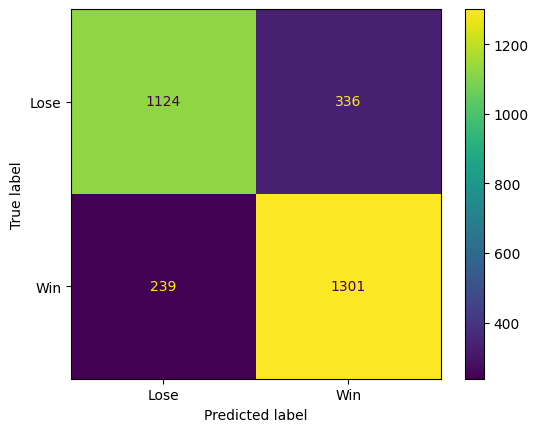

In [26]:
# Cria a matriz de confusão
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Lose", "Win"]).plot();

In [29]:
# Calcula a probabilidade de vitoria
probabilities = modelo_normalizado.predict_proba(X_test)
indice_vitoria = list(modelo_normalizado.classes_).index(1)

# Extraindo a probabilidade de vitória em porcentagem
chances_vitoria = probabilities[:, indice_vitoria] * 100

# Exibindo os resultados
resultados = pd.DataFrame({
    "Resultado real": y_test.values,
    "Chance de vitória (%)": chances_vitoria,
    "Previsão do modelo": modelo_normalizado.predict(X_test)
})

print(resultados)

      Resultado real  Chance de vitória (%)  Previsão do modelo
0                  1                   80.0                   1
1                  0                   80.0                   1
2                  0                   20.0                   0
3                  0                   40.0                   0
4                  0                   60.0                   1
...              ...                    ...                 ...
2995               1                   40.0                   0
2996               1                   80.0                   1
2997               0                    0.0                   0
2998               0                    0.0                   0
2999               0                   20.0                   0

[3000 rows x 3 columns]
